# Validating the simulated AGN catalog against SDSS

Checks the black hole masses, Eddington ratios and bolometric luminosities that
`QuasarHostMatch` assigns, against the SDSS DR7 quasar property catalog of
[Shen et al. (2011)](https://arxiv.org/abs/1006.5178), pulled from VizieR.

Compares two host catalogs: all galaxies (red hosts get $M_{\rm BH}$ from $M$-$\sigma$,
blue hosts from $M$-$M_*$) and red galaxies only. Both use the lognormal
Eddington ratio distribution of `QuasarHostMatch`.

In [1]:
import os, warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table, vstack
from astropy.cosmology import FlatLambdaCDM
from astropy.units import Quantity

import slsim
from slsim.Pipelines.skypy_pipeline import SkyPyPipeline
from slsim.Pipelines import roman_speclite
from slsim.Deflectors.MassLightConnection.velocity_dispersion import (
    vel_disp_abundance_matching,
)
from slsim.Sources.SourceCatalogues.QuasarCatalog.quasar_pop import QuasarRate
from slsim.Sources.SourceCatalogues.QuasarCatalog.quasar_host_match import (
    QuasarHostMatch,
    L_EDDINGTON_PER_MSUN,
    BLACK_HOLE_MASS_RELATIONS,
    ERDF_LOCATION,
    ERDF_WIDTH,
    log_black_hole_mass,
    log_bolometric_luminosity,
)

warnings.filterwarnings("ignore")
roman_speclite.configure_roman_filters()

DATA_DIR = "../data"
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
sky_area = Quantity(2.0, "deg2")
skypy_config = os.path.join(
    os.path.split(os.path.dirname(slsim.__file__))[0], "data/SkyPy/roman-lsst-like.yml"
)

COLORS = {"all": "tab:blue", "red": "tab:red"}
LABELS = {"all": "all hosts", "red": "red hosts only"}

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]


In [2]:
shen_path = os.path.join(DATA_DIR, "shen2011_dr7.fits")

if os.path.exists(shen_path):
    shen = Table.read(shen_path)
else:
    import pyvo

    tap = pyvo.dal.TAPService("https://tapvizier.cds.unistra.fr/TAPVizieR/tap")
    job = tap.submit_job(
        '''SELECT "z", "logLbol", "logBH", "logEdd", "iMAG"
           FROM "J/ApJS/194/45/catalog"
           WHERE "logBH" IS NOT NULL AND "logLbol" IS NOT NULL
             AND "iMAG" IS NOT NULL'''
    )
    job.run()
    job.wait(timeout=900)
    shen = job.fetch_result().to_table()
    shen.write(shen_path, overwrite=True)

for column in ["logBH", "logLbol", "logEdd", "iMAG"]:
    shen = shen[np.isfinite(shen[column])]
len(shen)

104746

In [3]:
hosts_path = os.path.join(DATA_DIR, f"hosts_{sky_area.value:g}deg2.fits")

if os.path.exists(hosts_path):
    hosts = Table.read(hosts_path)
else:
    pipeline = SkyPyPipeline(
        skypy_config=skypy_config, sky_area=sky_area, filters=None, cosmo=cosmo
    )
    red, blue = pipeline.red_galaxies, pipeline.blue_galaxies
    red["galaxy_type"], blue["galaxy_type"] = "red", "blue"
    hosts = vstack([red, blue], join_type="exact")
    hosts["vel_disp"] = vel_disp_abundance_matching(
        hosts, z_max=0.5, sky_area=sky_area, cosmo=cosmo
    )(np.log10(hosts["stellar_mass"]))
    hosts.write(hosts_path, overwrite=True)

len(hosts)

4702237

The SkyPy host catalog is overwhelmingly dwarf galaxies, which is what drives
the black hole masses low when blue hosts are allowed.

In [4]:
z, sigma = np.asarray(hosts["z"]), np.asarray(hosts["vel_disp"])
print(f"{'z bin':<10}{'N':>9}{'sigma p50':>11}{'p99':>7}{'max':>7}{'N(s>240)':>10}")
for lo, hi in [(0.2, 0.4), (0.4, 0.8), (0.8, 1.2), (1.2, 1.8), (1.8, 2.5), (2.5, 3.5)]:
    s = sigma[(z > lo) & (z < hi) & (sigma > 0)]
    print(f"{f'{lo}-{hi}':<10}{len(s):>9}{np.percentile(s, 50):>11.0f}"
          f"{np.percentile(s, 99):>7.0f}{s.max():>7.0f}{(s > 240).sum():>10}")

z bin             N  sigma p50    p99    max  N(s>240)
0.2-0.4      129968         29    121    318        17
0.4-0.8      421185         33    142    382       181
0.8-1.2      494774         36    161    425       514


1.2-1.8      722668         39    181    482      1840
1.8-2.5      754706         41    214    502      4370
2.5-3.5      935256         43    262    593     13415


In [5]:
quasar_rate = QuasarRate(
    skypy_config=skypy_config, cosmo=cosmo, sky_area=sky_area, noise=True,
    redshifts=np.linspace(0.001, 5.01, 100), use_qsogen_sed=False,
)
quasars = quasar_rate.quasar_sample(m_min=15, m_max=26, host_galaxy=False)

host_sets = {"all": hosts, "red": hosts[hosts["galaxy_type"] == "red"]}
matched = {}
for name, host_set in host_sets.items():
    matcher = QuasarHostMatch(quasars, host_set, rng=0, verbose=True)
    matched[name] = matcher.match()
    print(f"{name:<14} matched {len(matched[name])}  rejected {len(matcher.rejected_indices)}")

Matching quasars with host galaxies:   0%|          | 0/3620 [00:00<?, ?it/s]

Matching quasars with host galaxies:  18%|█▊        | 658/3620 [00:00<00:00, 6574.80it/s]

Matching quasars with host galaxies:  48%|████▊     | 1750/3620 [00:00<00:00, 9124.81it/s]

Matching quasars with host galaxies:  84%|████████▍ | 3043/3620 [00:00<00:00, 10859.72it/s]

Matching quasars with host galaxies: 100%|██████████| 3620/3620 [00:00<00:00, 10474.57it/s]

all            matched 3620  rejected 0


Matching quasars with host galaxies:   0%|          | 0/3620 [00:00<?, ?it/s]

Matching quasars with host galaxies:  67%|██████▋   | 2425/3620 [00:00<00:00, 24248.98it/s]

Matching quasars with host galaxies: 100%|██████████| 3620/3620 [00:00<00:00, 24701.16it/s]

red            matched 3620  rejected 0


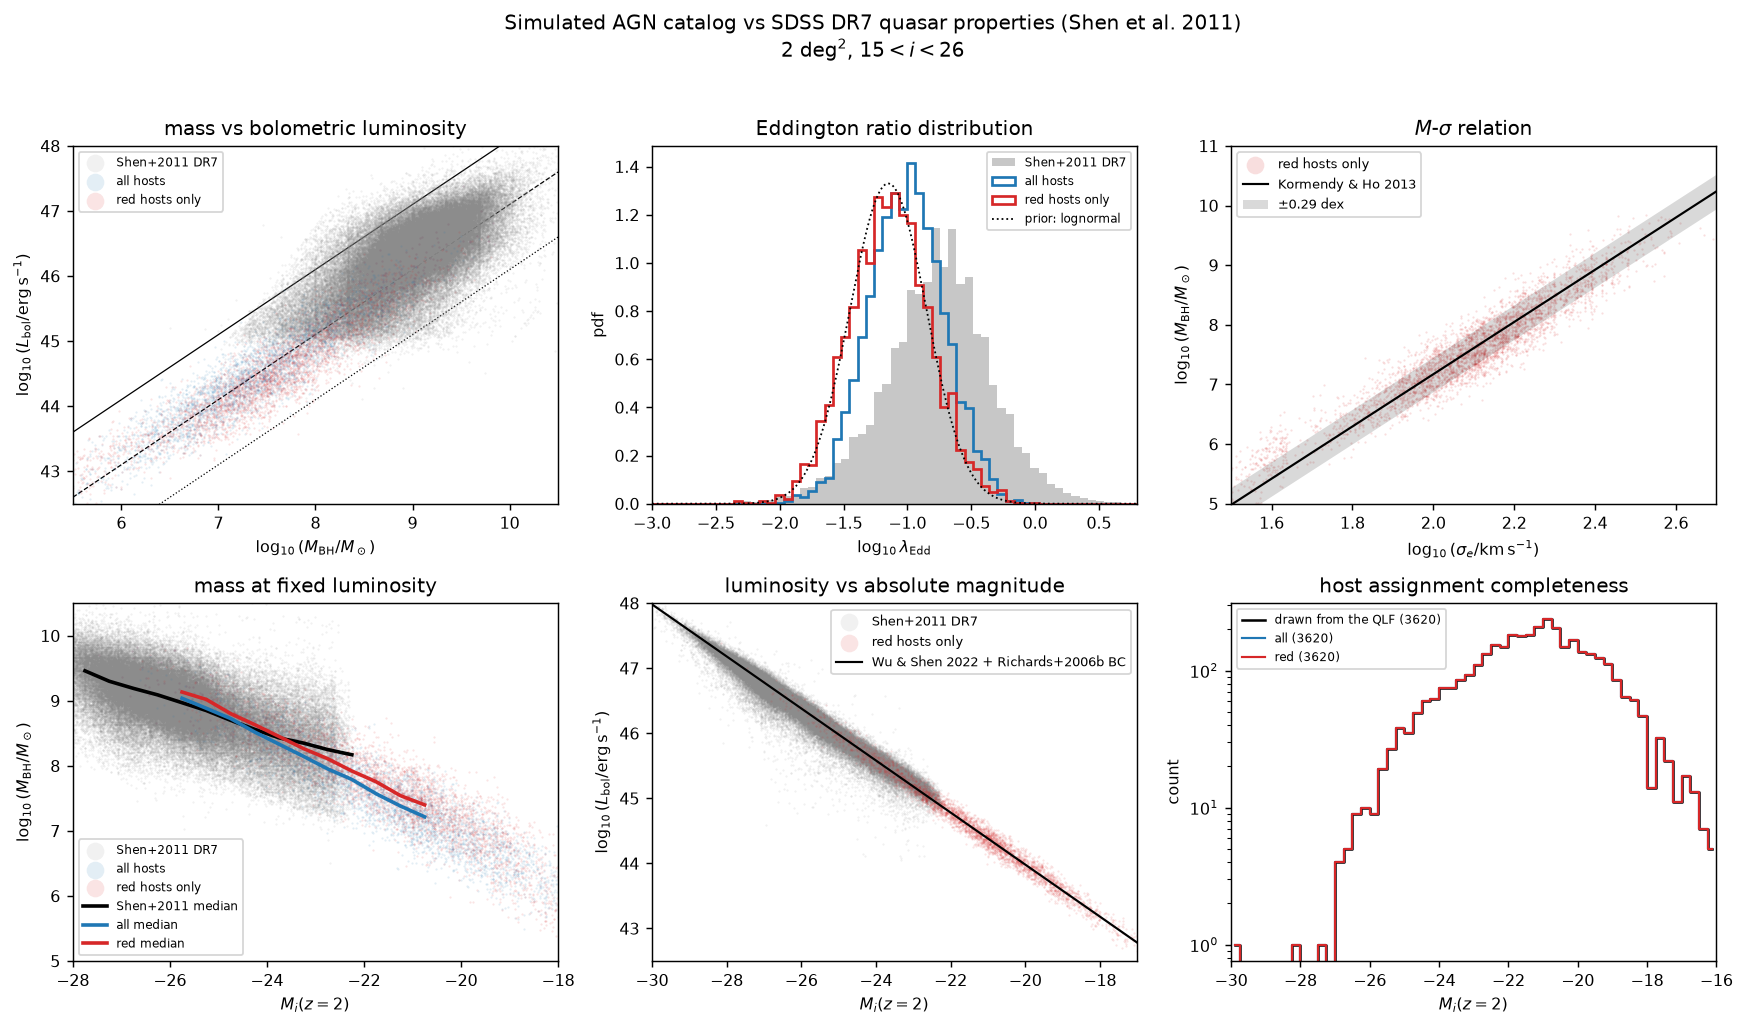

In [6]:
plt.rcParams.update({"font.size": 9, "figure.dpi": 130})
fig, ax = plt.subplots(2, 3, figsize=(13.5, 8))

def cloud(axis, x, y, color, label=None, alpha=0.12):
    axis.scatter(x, y, s=1.5, alpha=alpha, c=color, lw=0, rasterized=True, label=label)

a = ax[0, 0]
cloud(a, shen["logBH"], shen["logLbol"], "0.55", "Shen+2011 DR7")
for name, table in matched.items():
    cloud(a, table["black_hole_mass_exponent"], table["log_bolometric_luminosity"],
          COLORS[name], LABELS[name])
grid = np.linspace(5.5, 10.5, 10)
for ratio, style in zip([1.0, 0.1, 0.01], ["-", "--", ":"]):
    a.plot(grid, grid + np.log10(L_EDDINGTON_PER_MSUN * ratio), "k", ls=style,
           lw=0.7, zorder=0)
a.set(xlabel=r"$\log_{10}(M_{\rm BH}/M_\odot)$",
      ylabel=r"$\log_{10}(L_{\rm bol}/{\rm erg\,s^{-1}})$",
      xlim=(5.5, 10.5), ylim=(42.5, 48), title="mass vs bolometric luminosity")
a.legend(markerscale=8, fontsize=6.5, loc="upper left")

a = ax[0, 1]
bins = np.linspace(-3, 0.8, 60)
a.hist(shen["logEdd"], bins=bins, density=True, histtype="stepfilled",
       color="0.78", label="Shen+2011 DR7", zorder=0)
for name, table in matched.items():
    a.hist(np.log10(table["eddington_ratio"]), bins=bins, density=True,
           histtype="step", color=COLORS[name], lw=1.5, label=LABELS[name])
log_lam = np.linspace(bins[0], bins[-1], 500)
prior = np.exp(-0.5 * ((log_lam - ERDF_LOCATION) / ERDF_WIDTH) ** 2) / (
    ERDF_WIDTH * np.sqrt(2 * np.pi))
a.plot(log_lam, prior, "k:", lw=1, label="prior: lognormal")
a.set(xlabel=r"$\log_{10}\lambda_{\rm Edd}$", ylabel="pdf", xlim=(-3, 0.8),
      title="Eddington ratio distribution")
a.legend(fontsize=6.5)

a = ax[0, 2]
cloud(a, np.log10(matched["red"]["vel_disp"]),
      matched["red"]["black_hole_mass_exponent"], "tab:red",
      LABELS["red"], alpha=0.15)
grid = np.linspace(1.5, 2.7, 50)
mean, scatter = log_black_hole_mass(np.full(grid.shape, "red"), vel_disp=10**grid)
a.plot(grid, mean, "k-", lw=1.2, label="Kormendy & Ho 2013")
a.fill_between(grid, mean - scatter, mean + scatter, color="k", alpha=0.15, lw=0,
               label=rf"$\pm{scatter[0]:.2f}$ dex")
a.set(xlabel=r"$\log_{10}(\sigma_e/{\rm km\,s^{-1}})$",
      ylabel=r"$\log_{10}(M_{\rm BH}/M_\odot)$", xlim=(1.5, 2.7), ylim=(5, 11),
      title=r"$M$-$\sigma$ relation")
a.legend(markerscale=8, fontsize=7, loc="upper left")

a = ax[1, 0]
cloud(a, shen["iMAG"], shen["logBH"], "0.55", "Shen+2011 DR7")
for name, table in matched.items():
    cloud(a, table["M_i"], table["black_hole_mass_exponent"], COLORS[name],
          LABELS[name])
edges = np.arange(-28, -20, 0.5)
series = [(np.asarray(shen["iMAG"]), np.asarray(shen["logBH"]), "k", "Shen+2011")]
series += [(np.asarray(t["M_i"]), np.asarray(t["black_hole_mass_exponent"]),
            COLORS[n], n) for n, t in matched.items()]
for x, y, color, label in series:
    index = np.digitize(x, edges)
    centres = [0.5 * (edges[b - 1] + edges[b]) for b in range(1, len(edges))
               if (index == b).sum() > 20]
    medians = [np.median(y[index == b]) for b in range(1, len(edges))
               if (index == b).sum() > 20]
    a.plot(centres, medians, color=color, lw=2, label=label + " median")
a.set(xlabel=r"$M_i(z=2)$", ylabel=r"$\log_{10}(M_{\rm BH}/M_\odot)$",
      xlim=(-28, -18), ylim=(5, 10.5), title="mass at fixed luminosity")
a.legend(markerscale=8, fontsize=6.5, loc="lower left")

a = ax[1, 1]
cloud(a, shen["iMAG"], shen["logLbol"], "0.55", "Shen+2011 DR7")
cloud(a, matched["red"]["M_i"],
      matched["red"]["log_bolometric_luminosity"], "tab:red", LABELS["red"])
grid = np.linspace(-30, -17, 50)
a.plot(grid, log_bolometric_luminosity(grid), "k-", lw=1.2,
       label="Wu & Shen 2022 + Richards+2006b BC")
a.set(xlabel=r"$M_i(z=2)$", ylabel=r"$\log_{10}(L_{\rm bol}/{\rm erg\,s^{-1}})$",
      xlim=(-30, -17), ylim=(42.5, 48), title="luminosity vs absolute magnitude")
a.legend(markerscale=8, fontsize=7, loc="upper right")

a = ax[1, 2]
bins = np.linspace(-30, -16, 57)
centres = 0.5 * (bins[1:] + bins[:-1])
a.step(centres, np.histogram(quasars["M_i"], bins=bins)[0], where="mid",
       color="k", lw=1.4, label=f"drawn from the QLF ({len(quasars)})")
for name, table in matched.items():
    a.step(centres, np.histogram(table["M_i"], bins=bins)[0], where="mid",
           color=COLORS[name], lw=1.2, label=f"{name} ({len(table)})")
a.set_yscale("log")
a.set(xlabel=r"$M_i(z=2)$", ylabel="count", xlim=(-30, -16),
      title="host assignment completeness")
a.legend(fontsize=6.5)

fig.suptitle("Simulated AGN catalog vs SDSS DR7 quasar properties "
             f"(Shen et al. 2011)\n{sky_area.value:g} deg$^2$, $15<i<26$",
             fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig("../figures/agn_catalog_validation.png", dpi=150, bbox_inches="tight")

The bright subset is the only range where SDSS DR7 and this catalog overlap,
so it is the only fair like-for-like comparison.

In [7]:
def percentiles(values):
    return np.round(np.nanpercentile(np.asarray(values), [16, 50, 84]), 2)

bright = (shen["iMAG"] > -26) & (shen["iMAG"] < -24)
print(f"{'':<34}{'log M_BH':<24}{'log lambda'}")
for name, table in matched.items():
    sub = (np.asarray(table["M_i"]) > -26) & (np.asarray(table["M_i"]) < -24)
    print(f"{name:<34}"
          f"{str(percentiles(np.asarray(table['black_hole_mass_exponent'])[sub])):<24}"
          f"{percentiles(np.log10(np.asarray(table['eddington_ratio'])[sub]))}")
print(f"{'Shen+2011 DR7':<34}{str(percentiles(shen['logBH'][bright])):<24}"
      f"{percentiles(shen['logEdd'][bright])}")

red = matched["red"]
residual = red["black_hole_mass_exponent"] - log_black_hole_mass(
    red["galaxy_type"], vel_disp=red["vel_disp"])[0]
print(f"\nM-sigma residual: mean {np.mean(residual):+.3f}, std {np.std(residual):.3f} dex "
      f"(input scatter {BLACK_HOLE_MASS_RELATIONS['red']['scatter']})")

check = matched["all"]
closure = check["log_bolometric_luminosity"] - (
    check["black_hole_mass_exponent"] + np.log10(L_EDDINGTON_PER_MSUN)
    + np.log10(check["eddington_ratio"])
)
print(f"L_bol = lambda * L_Edd(M_BH) closure: max |residual| "
      f"{np.abs(closure).max():.2e} dex")

                                  log M_BH                log lambda
all                               [8.39 8.7  9.08]        [-1.26 -0.95 -0.67]
red                               [8.48 8.8  9.17]        [-1.35 -1.03 -0.76]
Shen+2011 DR7                     [8.43 8.83 9.19]        [-1.23 -0.86 -0.51]

M-sigma residual: mean -0.004, std 0.298 dex (input scatter 0.29)
L_bol = lambda * L_Edd(M_BH) closure: max |residual| 7.11e-15 dex


In [8]:
pipeline = SkyPyPipeline(
        skypy_config=skypy_config, sky_area=sky_area, filters=None, cosmo=cosmo
    )
red, blue = pipeline.red_galaxies, pipeline.blue_galaxies
red["galaxy_type"], blue["galaxy_type"] = "red", "blue"
hosts = vstack([red, blue], join_type="exact")


In [9]:
hosts_extended = hosts.copy()
hosts_extended["vel_disp"] = vel_disp_abundance_matching(
    hosts_extended, z_max=.5, sky_area=sky_area, cosmo=cosmo
)(np.log10(hosts_extended["stellar_mass"]))
hosts_extended

z,M,coeff,ellipticity,physical_size,stellar_mass,angular_size,mag_F062,mag_F087,mag_F106,mag_F129,mag_F158,mag_F184,mag_F146,mag_F213,mag_g,mag_r,mag_i,mag_z,mag_y,galaxy_type,vel_disp
,,,,kpc,,arcsec,,,,,,,,,,,,,,,
float64,float64,float64[5],float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str4,float64
1.0020446581043294,-18.38816257557276,0.13580378267935636 .. 0.0017639506548609348,0.07983344453635291,0.3171934572580695,16219601683.155228,0.03958700823572883,26.832800051432827,25.015754000956797,24.299437519722446,23.8298635827204,23.44791685714788,23.169634904466804,23.650475760057176,22.92425300061528,28.324471073553852,26.93392241346082,25.965155465916837,25.010940830519132,24.528335313228453,red,78.34860404321643
0.7697205735753118,-20.908586813857283,0.06688340973003548 .. 0.0005412175571036296,0.07612229713020852,3.2162054862055798,136258190352.01192,0.43416709042277857,22.943450409091298,21.473646299014682,20.992297865966222,20.636370903819618,20.325746740488867,20.0816540860838,20.499399937190873,19.983090818918306,24.356301580804164,23.155495695533197,22.002198484060344,21.455664695367858,21.191498548035234,red,159.62045176919332
2.4318991680942563,-21.518156641452677,0.09219240849301609 .. 0.0008763928093196788,0.08524843932057728,4.207546535493373,261064000198.1421,0.518238619590836,25.99519684758126,25.87861546506311,25.281158337544614,24.438660258997015,23.430736249487726,22.97390093160487,23.788998637032325,22.630128006700257,26.06160527574762,25.996343148251857,25.911848494263726,25.904896566196836,25.664164446608627,red,200.76637653927986
0.5456509971515123,-20.85213341252341,0.3367381595034962 .. 0.000748246086566278,0.1947836069125536,2.230909592743787,148391082217.73718,0.34932956904680773,21.497682414039552,20.35672199536058,19.88157425182667,19.477096936611204,19.064755993927825,18.84931478171051,19.288868790575066,18.708552381572602,22.85960087265412,21.646389327070466,20.75750938192708,20.35233098825534,20.06293836343854,red,163.87759682738442
1.3094537164655842,-20.780264952948162,0.013236558390342736 .. 0.00010344186280642028,0.6008369294185603,1.8327533159457448,137764058651.46472,0.21859555772165395,26.021456049565966,24.068423211787998,22.94672697921335,22.35812881317351,21.955234652443227,21.69404724621886,22.194934514743306,21.483892202731536,27.65677339033883,26.43734219436335,24.898348671613693,24.235807879982364,23.35823256741018,red,160.16304580757935
3.1741134135737608,-19.86416110509643,0.04098274278856367 .. 0.0011707633969288982,0.15645818528415859,2.0477236955107756,53917590181.04168,0.2704972916762449,29.01206872520495,28.75913595514503,28.559635166750166,27.602205854533143,26.597546056742214,25.715559484455785,26.754329151787235,25.251712741759757,29.17553649901605,29.03503345631429,28.887075044787412,28.733164323065626,28.71038923743531,red,119.86754454315144
2.244758014932019,-18.29102115600602,0.05777940407266682 .. 0.0018584010830239822,0.36506064578616765,0.19267638398282744,8000774511.748316,0.023384933007538956,28.132457755250073,28.064584696905655,27.744991627154775,27.06859321511046,26.43827413368261,26.15330709807982,26.745649794048475,25.874008037317445,28.205861410254613,28.119069490741694,28.097742032374505,28.085869080937258,27.90508238699458,red,55.536394159330335
1.4157278035733256,-20.89858418613908,0.1712755657779885 .. 0.0005983719190139316,0.4745112701149746,2.5261801698462865,154128134988.88962,0.29935411562685565,25.698529399705368,24.335297846090075,23.19381909269112,22.507858478378214,22.04683704660655,21.743800656475248,22.302997561662426,21.496057378126142,26.1013857922668,25.917964001949077,24.977089967114527,24.39737904742255,23.718762509640786,red,166.7519902894426


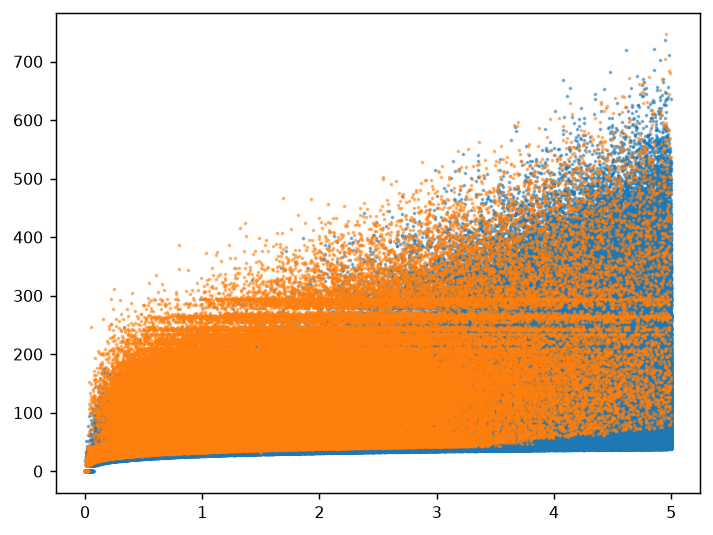

In [10]:
# plt.scatter(hosts_extended["z"], hosts_extended["vel_disp"], s=1, alpha=0.1)
blue_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "blue"]
plt.scatter(blue_galaxies["z"], blue_galaxies["vel_disp"], s=1, alpha=0.5)
red_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "red"]
plt.scatter(red_galaxies["z"], red_galaxies["vel_disp"], s=1, alpha=0.5)

In [11]:
len(blue_galaxies), len(red_galaxies)

(4419043, 280214)

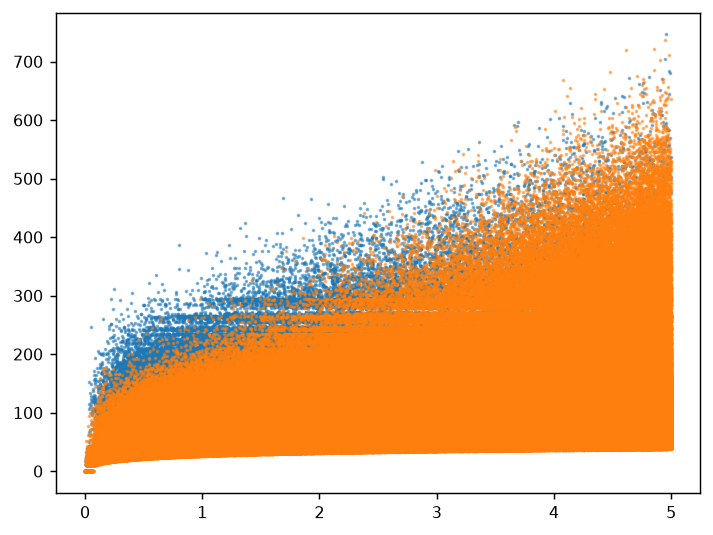

In [12]:
# plt.scatter(hosts_extended["z"], hosts_extended["vel_disp"], s=1, alpha=0.1)
red_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "red"]
plt.scatter(red_galaxies["z"], red_galaxies["vel_disp"], s=1, alpha=0.5)
blue_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "blue"]
plt.scatter(blue_galaxies["z"], blue_galaxies["vel_disp"], s=1, alpha=0.5)

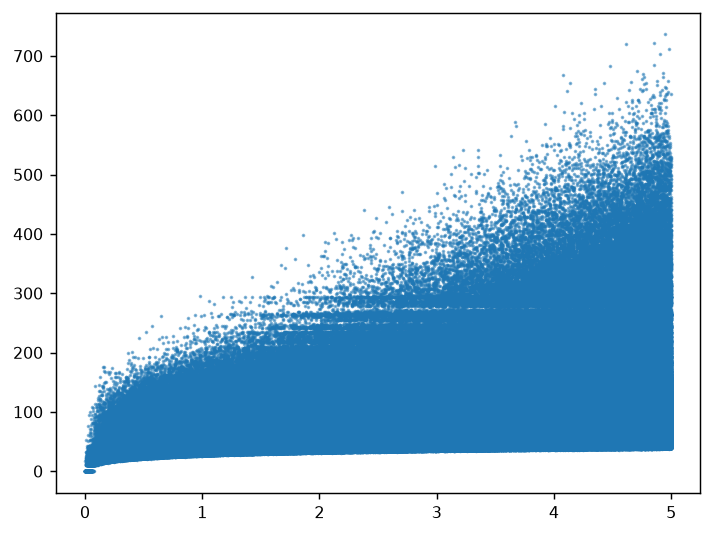

In [13]:
# plt.scatter(hosts_extended["z"], hosts_extended["vel_disp"], s=1, alpha=0.1)
# red_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "red"]
# plt.scatter(red_galaxies["z"], red_galaxies["vel_disp"], s=1, alpha=0.5)
blue_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "blue"]
plt.scatter(blue_galaxies["z"], blue_galaxies["vel_disp"], s=1, alpha=0.5)

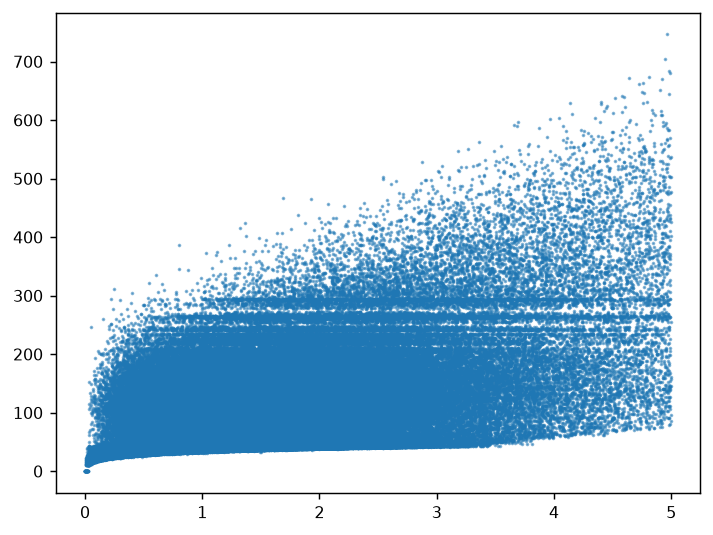

In [14]:
# plt.scatter(hosts_extended["z"], hosts_extended["vel_disp"], s=1, alpha=0.1)
red_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "red"]
plt.scatter(red_galaxies["z"], red_galaxies["vel_disp"], s=1, alpha=0.5)
# blue_galaxies = hosts_extended[hosts_extended["galaxy_type"] == "blue"]
# plt.scatter(blue_galaxies["z"], blue_galaxies["vel_disp"], s=1, alpha=0.5)

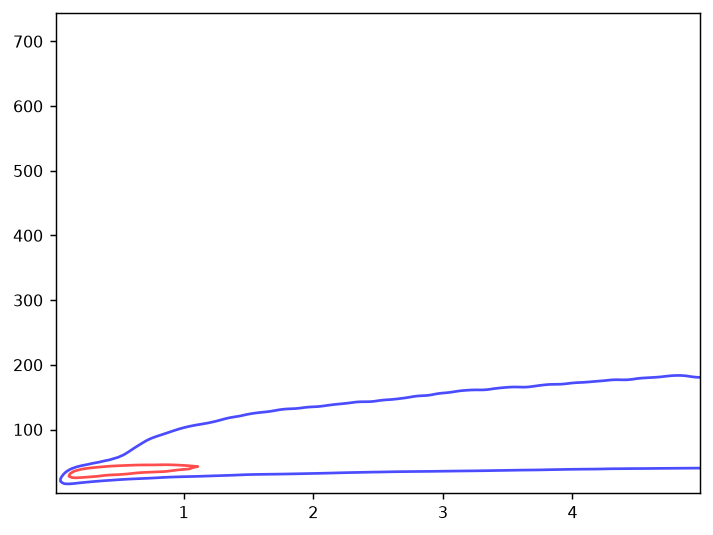

In [15]:
# contours of the red and blue galaxies in the z vs vel_disp plane

import numpy as np
import matplotlib.pyplot as plt

# Adjust 'bins' to change the resolution/smoothness of the contours
bins = 200 

for gal_type, color in [("red", "red"), ("blue", "blue")]:
    subset = hosts_extended[hosts_extended["galaxy_type"] == gal_type]
    
    # 1. Instantly calculate density grid via NumPy 2D histogram
    H, xedges, yedges = np.histogram2d(subset["z"], subset["vel_disp"], bins=bins)
    H = np.log10(H + 1)  # Log scale for better visualization

    # make it smoother by applying a Gaussian filter
    from scipy.ndimage import gaussian_filter
    H = gaussian_filter(H, sigma=2)
    
    # 2. Get bin centers for plotting
    x_centers = (xedges[:-1] + xedges[1:]) / 2
    y_centers = (yedges[:-1] + yedges[1:]) / 2
    
    # 3. Plot contours (H.T transposes the matrix to align with x,y coords)
    # Increase 'levels' to show more contour rings
    plt.contour(x_centers, y_centers, H.T, colors=color, alpha=0.7, levels=[2])

plt.show()

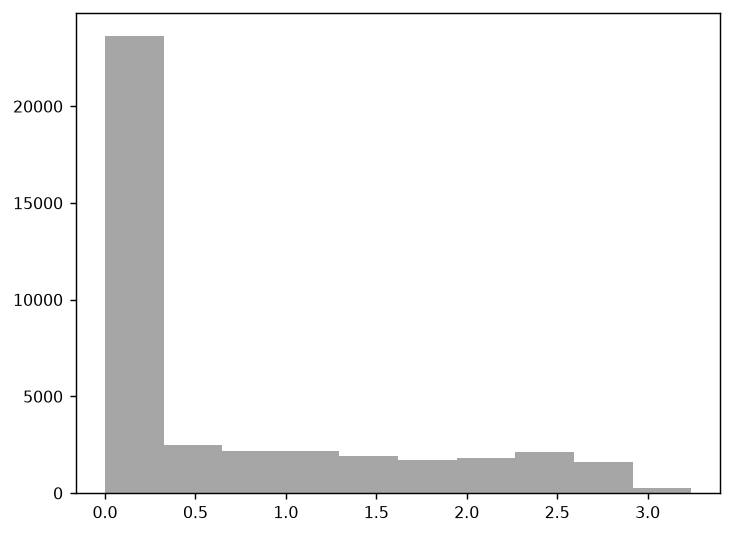

In [16]:
plt.hist(H.flatten(), bins=10, color='gray', alpha=0.7);